# Phase 4: Reviewer-Driven Experiments (CrisisMMD++)

This notebook runs the extra experiments requested by the IEEE BigData 2026 reviewers.


| Experiment | What it does | Reviewer problem it addresses |
|---|---|---|
| **1. Multi-seed replication** | Re-runs the Phase 3 comparison (human vs LLM labels) with 5 seeds, reports mean ± std, significance tests, and majority-class baselines | Single-seed results; R1: "a classifier may achieve higher accuracy simply by reproducing the distribution" (class-prior baseline) |
| **2. Duplicate-free splits** | Groups exact (MD5), near-duplicate (pHash ≤ 5) and duplicate-text rows, keeps each group in one split, and compares against random splits. Optional: leave-one-event-out | R1: overlap between partitions is identified but not removed; event-disjoint evaluation |
| **3. Equal class frequency** | Trains and tests on class-balanced data (same number of severe / mild / little-or-no damage) | R1: generated labels are 87.65% severe, so the classifier may just learn the distribution |
| **4. Both-label damage subset** | On the 3,627 rows with both human and LLM labels, trains on human, LLM, or consensus labels and evaluates every model on human, LLM and consensus test labels | R1: comparison does not isolate annotation quality from training-set composition |
| **5. Resampling + coverage** | (A) resamples LLM training labels to the human class distribution; (B) adds the 7,915 new LLM labels to human training data and tests on the same human test set | R1: controlled label distributions, then the benefit of expanding coverage |

## How to run
1. **Always run the 5 Setup cells first** (S1 to S5). They are fast after the first time because text embeddings and image features are cached on disk.
2. Then run **only the cells of the experiment you want** (for example the two cells under Experiment 3).
3. Each experiment also has a **Summary cell** that reads the saved CSV, so you can make tables again without retraining.



All outputs go to `thesis_analysis_results/phase4_reviewer_experiments/`.

## Setup S1: imports, settings and paths

In [25]:

import os, re, json, time, pickle, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             precision_recall_fscore_support)
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.models import DenseNet121_Weights

import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DEVICE = torch.device('cpu')

# Training settings
BATCH_SIZE              = 16
EPOCHS                  = 15
WEIGHT_DECAY            = 1e-4
EARLY_STOPPING_PATIENCE = 5
BERT_MODEL_NAME         = 'distilbert-base-uncased'

# Seeds
SEEDS_EXP1  = [15, 42, 123, 2024, 7]   # Experiment 1 (multi-seed)
SEEDS_OTHER = [15, 42, 123]            # Experiments 2-5

# Model configurations (same names as Phase 3)
CONFIGS = {
    'A — Baseline':          dict(d_model=256, lr=1e-4, dropout=0.20, n_heads=4, freeze_image=True),
    'B — Larger Model':      dict(d_model=512, lr=1e-4, dropout=0.20, n_heads=8, freeze_image=True),
    'C — Unfrozen Backbone': dict(d_model=256, lr=1e-4, dropout=0.30, n_heads=4, freeze_image=False),
    'D — Larger + Unfrozen': dict(d_model=512, lr=3e-5, dropout=0.30, n_heads=8, freeze_image=False),
}
# Frozen configs (A, B) use cached DenseNet features and are fast.
# Unfrozen configs (C, D) load every image each epoch and are MUCH slower on CPU.
RUN_CONFIGS = ['A — Baseline', 'B — Larger Model']
USE_CACHED_IMAGE_FEATURES = True

# Paths
def find_project_root(marker='CrisisMMD_v2.0'):
    for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (c / marker).is_dir():
            return c
    raise FileNotFoundError(f"Cannot find '{marker}' from {Path.cwd()}")

PROJECT_ROOT = find_project_root()
CRISIS_ROOT  = PROJECT_ROOT / 'CrisisMMD_v2.0'
DATA_CSV     = PROJECT_ROOT / 'CrisisMMD_PlusPlus_Final_Labels.csv'
CACHE_DIR    = PROJECT_ROOT / 'cache'
P4_DIR       = PROJECT_ROOT / 'thesis_analysis_results' / 'phase4_reviewer_experiments'
CKPT_DIR     = P4_DIR / 'checkpoints'
PRED_DIR     = P4_DIR / 'predictions'
for d in (CACHE_DIR, P4_DIR, CKPT_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

print(f'Project root : {PROJECT_ROOT}')
print(f'Results dir  : {P4_DIR}')
print(f'Configs      : {RUN_CONFIGS}   cached image features: {USE_CACHED_IMAGE_FEATURES}')

Project root : C:\Users\ynjis\Downloads\crisisMMDDataSet
Results dir  : C:\Users\ynjis\Downloads\crisisMMDDataSet\thesis_analysis_results\phase4_reviewer_experiments
Configs      : ['A — Baseline', 'B — Larger Model']   cached image features: True


## Setup S2: load data, duplicate groups and split helpers

In [26]:

df_all = pd.read_csv(DATA_CSV, low_memory=False)
df_all['row_id'] = np.arange(len(df_all))
df_all['full_image_path'] = df_all['image_path'].apply(lambda p: str(CRISIS_ROOT / str(p)))
_exists = df_all['full_image_path'].map(os.path.exists)
if (~_exists).sum():
    print(f'WARNING: {(~_exists).sum()} rows have missing image files and are dropped')
df_all = df_all[_exists].reset_index(drop=True)
df_all['tweet_text'] = df_all['tweet_text'].fillna('').astype(str)

SEV4 = ['severe_damage', 'mild_damage', 'little_or_no_damage', 'dont_know_or_cant_judge']
SEV3 = SEV4[:3]
HUM_CLASSES = sorted(set(df_all['text_human']) | set(df_all['text_llm']))

# Rows with an ORIGINAL human damage label (image_damage_conf is only set for those)
df_all['has_human_damage'] = df_all['image_damage_conf'].notna()
BOTH    = df_all[df_all.has_human_damage & df_all.image_damage_llm.isin(SEV4)].reset_index(drop=True)
NEW_LLM = df_all[~df_all.has_human_damage & df_all.image_damage_llm.isin(SEV3)].reset_index(drop=True)
print(f'All rows: {len(df_all)} | both-label damage rows: {len(BOTH)} | new concrete LLM damage rows: {len(NEW_LLM)}')

# ── Duplicate groups (MD5 exact, pHash Hamming <= 5, identical normalised text) ─
PHASH_MAX_DIST = 5
TEXT_MIN_LEN   = 25          # very short texts are not treated as duplicates
DUP_CACHE      = P4_DIR / 'duplicate_groups.csv'

def _norm_text(t):
    t = re.sub(r'https?://\S+', ' ', str(t).lower())
    t = re.sub(r'^rt @\w+:?', ' ', t)
    t = re.sub(r'[^a-z0-9#@ ]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def build_duplicate_groups(df):
    n = len(df); parent = np.arange(n)
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    def union(i, j):
        ri, rj = find(i), find(j)
        if ri != rj: parent[rj] = ri
    # exact MD5 and normalised text
    for key in ['image_hash', '_ntext']:
        for _, idx in df.groupby(key).indices.items():
            if key == '_ntext' and len(df['_ntext'].iloc[idx[0]]) < TEXT_MIN_LEN:
                continue
            for j in idx[1:]: union(idx[0], j)
    # near-duplicate pHash (chunked popcount)
    h = np.array([int(x, 16) for x in df['perceptual_hash']], dtype=np.uint64)
    pop8 = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
    for s in tqdm(range(0, n, 500), desc='pHash near-duplicates'):
        x = (h[s:s+500, None] ^ h[None, :])
        dist = pop8[x.view(np.uint8).reshape(x.shape[0], n, 8)].sum(-1)
        ii, jj = np.where(dist <= PHASH_MAX_DIST)
        for a, b in zip(ii + s, jj):
            if b > a: union(a, b)
    return np.array([find(i) for i in range(n)])

if DUP_CACHE.exists():
    _g = pd.read_csv(DUP_CACHE)
    df_all = df_all.drop(columns=['dup_group'], errors='ignore').merge(_g, on='row_id', how='left')
    print(f'Loaded duplicate groups from {DUP_CACHE.name}')
else:
    df_all['_ntext'] = df_all['tweet_text'].map(_norm_text)
    df_all['dup_group'] = build_duplicate_groups(df_all)
    df_all = df_all.drop(columns=['_ntext'])
    df_all[['row_id', 'dup_group']].to_csv(DUP_CACHE, index=False)
    print(f'Built and saved duplicate groups → {DUP_CACHE.name}')
_gs = df_all.groupby('dup_group').size()
print(f'Duplicate groups: {(_gs > 1).sum()} groups with >1 row, covering {_gs[_gs > 1].sum()} rows')

# refresh subsets so they carry dup_group
BOTH    = df_all[df_all.has_human_damage & df_all.image_damage_llm.isin(SEV4)].reset_index(drop=True)
NEW_LLM = df_all[~df_all.has_human_damage & df_all.image_damage_llm.isin(SEV3)].reset_index(drop=True)

# Split helpers
def _can_stratify(labels, test_size):
    c = labels.value_counts(); n = len(labels); nt = max(1, int(np.ceil(n * test_size)))
    return c.min() >= 2 and (n - nt) >= len(c) and nt >= len(c)

def split_random(df, strat_col, seed):
    """70/15/15 split exactly like Phase 3 (stratified when possible)."""
    s1 = df[strat_col] if _can_stratify(df[strat_col], 0.3) else None
    tr, tmp = train_test_split(df, test_size=0.3, random_state=seed, stratify=s1)
    s2 = tmp[strat_col] if _can_stratify(tmp[strat_col], 0.5) else None
    vl, te = train_test_split(tmp, test_size=0.5, random_state=seed, stratify=s2)
    return tr.reset_index(drop=True), vl.reset_index(drop=True), te.reset_index(drop=True)

def split_grouped(df, strat_col, seed, group_col='dup_group'):
    """≈70/15/15 split where every duplicate group stays in ONE partition."""
    sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=seed)
    fold = np.zeros(len(df), dtype=int)
    for k, (_, idx) in enumerate(sgkf.split(df, df[strat_col], df[group_col])):
        fold[idx] = k
    tr, vl, te = df[fold < 14], df[(fold >= 14) & (fold < 17)], df[fold >= 17]
    return tr.reset_index(drop=True), vl.reset_index(drop=True), te.reset_index(drop=True)

def make_split(df, strat_col, seed, mode):
    return split_grouped(df, strat_col, seed) if mode == 'dedup' else split_random(df, strat_col, seed)

def leak_report(tr, vl, te):
    out = {}
    for a, b, name in [(tr, vl, 'train-val'), (tr, te, 'train-test'), (vl, te, 'val-test')]:
        out[f'{name} md5']   = len(set(a.image_hash) & set(b.image_hash))
        out[f'{name} phash'] = len(set(a.perceptual_hash) & set(b.perceptual_hash))
        out[f'{name} group'] = len(set(a.dup_group) & set(b.dup_group))
    return out

SETUP_S2_DONE = True

All rows: 18082 | both-label damage rows: 3627 | new concrete LLM damage rows: 7915
Loaded duplicate groups from duplicate_groups.csv
Duplicate groups: 1619 groups with >1 row, covering 4589 rows


## Setup S3: DistilBERT text embeddings (cached)

In [27]:

BERT_CACHE = CACHE_DIR / f'bert_cls_{BERT_MODEL_NAME.replace("/", "_")}.pkl'
bert_cache = pickle.load(open(BERT_CACHE, 'rb')) if BERT_CACHE.exists() else {}
_missing = sorted({t for t in df_all['tweet_text'] if t not in bert_cache})
if _missing:
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
    bert = AutoModel.from_pretrained(BERT_MODEL_NAME).eval()
    with torch.no_grad():
        for i in tqdm(range(0, len(_missing), 32), desc='BERT encoding'):
            batch = _missing[i:i+32]
            enc = tok(batch, padding=True, truncation=True, max_length=128, return_tensors='pt')
            cls = bert(**enc).last_hidden_state[:, 0, :].numpy().astype(np.float32)
            for t, e in zip(batch, cls): bert_cache[t] = e
    pickle.dump(bert_cache, open(BERT_CACHE, 'wb'))
    del tok, bert
print(f'BERT cache: {len(bert_cache)} texts ({len(_missing)} newly encoded)')
TEXT_DIM = len(next(iter(bert_cache.values())))

def text_emb(df):
    return np.stack([bert_cache[t] for t in df['tweet_text']]).astype(np.float32)

BERT cache: 16058 texts (0 newly encoded)


## Setup S4: DenseNet121 image features (cached, resumable)
Frozen configs (A, B) never update the image encoder, so each image's 1024-d feature is computed once and saved.
This makes each training run take minutes instead of hours on CPU.
The first time, this cell takes roughly 20-40 minutes for 18,082 images. It saves every 500 images, so a shutdown loses little work.

*Note:* features are extracted with the encoder in evaluation mode (BatchNorm statistics fixed), which is the strict meaning of a frozen backbone.
Phase 3 kept BatchNorm in training mode, so absolute numbers can differ slightly from Phase 3.

In [28]:

_weights = DenseNet121_Weights.IMAGENET1K_V1
image_transform = _weights.transforms()
FEAT_CACHE = CACHE_DIR / 'densenet121_eval_features.pkl'
img_feat_cache = pickle.load(open(FEAT_CACHE, 'rb')) if FEAT_CACHE.exists() else {}

if USE_CACHED_IMAGE_FEATURES:
    todo = [p for p in df_all['full_image_path'] if p not in img_feat_cache]
    if todo:
        enc = models.densenet121(weights=_weights).features.eval()
        pool = nn.AdaptiveAvgPool2d((1, 1))
        with torch.no_grad():
            for i in tqdm(range(0, len(todo), 32), desc='DenseNet features'):
                paths = todo[i:i+32]
                x = torch.stack([image_transform(Image.open(p).convert('RGB')) for p in paths])
                f = pool(enc(x)).flatten(1).numpy().astype(np.float32)
                for p, v in zip(paths, f): img_feat_cache[p] = v
                if (i // 32) % 16 == 15:                       # every ~500 images
                    pickle.dump(img_feat_cache, open(FEAT_CACHE, 'wb'))
        pickle.dump(img_feat_cache, open(FEAT_CACHE, 'wb'))
        del enc
    print(f'Image feature cache: {len(img_feat_cache)} images ({len(todo)} newly computed)')

def img_feats(df):
    return np.stack([img_feat_cache[p] for p in df['full_image_path']]).astype(np.float32)

Image feature cache: 18082 images (0 newly computed)


## Setup S5: model, training engine, metrics and crash-safe result logging

In [29]:

class FeatDataset(Dataset):
    def __init__(self, img, txt, y): self.img, self.txt, self.y = img, txt, y
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return (torch.from_numpy(self.img[i]), torch.from_numpy(self.txt[i]),
                torch.tensor(int(self.y[i]), dtype=torch.long))

class ImageDataset(Dataset):
    def __init__(self, paths, txt, y): self.paths, self.txt, self.y = list(paths), txt, y
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = image_transform(Image.open(self.paths[i]).convert('RGB'))
        return x, torch.from_numpy(self.txt[i]), torch.tensor(int(self.y[i]), dtype=torch.long)

class FusionHead(nn.Module):
    """Same fusion as Phase 3: project text + image → 2 tokens → MHA → residual+LN → mean → MLP."""
    def __init__(self, text_dim, num_classes, d_model, n_heads, dropout):
        super().__init__()
        self.image_proj = nn.Linear(1024, d_model)
        self.text_proj  = nn.Linear(text_dim, d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.norm = nn.LayerNorm(d_model)
        self.classifier = nn.Sequential(nn.Linear(d_model, d_model // 2), nn.ReLU(),
                                        nn.Dropout(dropout), nn.Linear(d_model // 2, num_classes))
    def forward(self, img_feat, txt):
        tokens = torch.stack([self.text_proj(txt), self.image_proj(img_feat)], dim=1)
        a, _ = self.attn(tokens, tokens, tokens)
        return self.classifier(self.norm(tokens + a).mean(dim=1))

class FullModel(nn.Module):
    """DenseNet121 encoder + FusionHead (used for unfrozen configs, or if caching is off)."""
    def __init__(self, text_dim, num_classes, d_model, n_heads, dropout, freeze_image):
        super().__init__()
        self.image_encoder = models.densenet121(weights=_weights).features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        if freeze_image:
            for p in self.image_encoder.parameters(): p.requires_grad = False
        self.head = FusionHead(text_dim, num_classes, d_model, n_heads, dropout)
    def forward(self, images, txt):
        return self.head(self.pool(self.image_encoder(images)).flatten(1), txt)

def _use_cache(hp): return USE_CACHED_IMAGE_FEATURES and hp['freeze_image']

def _loader(df, y, hp, shuffle, seed):
    txt = text_emb(df)
    ds = FeatDataset(img_feats(df), txt, y) if _use_cache(hp) else ImageDataset(df['full_image_path'], txt, y)
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0, generator=g)

def _class_weights(y, nc):
    c = np.bincount(y, minlength=nc); n = len(y)
    return torch.tensor([n / (nc * max(c[i], 1)) for i in range(nc)], dtype=torch.float32)

def _predict(model, loader):
    model.eval(); out = []
    with torch.no_grad():
        for a, b, _ in loader: out.append(model(a, b).argmax(1).numpy())
    return np.concatenate(out)

def compute_metrics(y_true, y_pred, classes):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    m = {'n_test': len(y_true),
         'accuracy': accuracy_score(y_true, y_pred),
         'weighted_f1': f1_score(y_true, y_pred, average='weighted', zero_division=0),
         'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
         'balanced_acc': balanced_accuracy_score(y_true, y_pred)}
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=classes, zero_division=0)
    for c, ri, fi, si in zip(classes, r, f, s):
        m[f'recall_{c}'] = ri; m[f'f1_{c}'] = fi; m[f'support_{c}'] = si
    return m

def baseline_metrics(y_train, y_test, classes, seed):
    """Majority-class and prior-sampling (class-frequency) baselines."""
    rows = []
    maj = pd.Series(y_train).value_counts().idxmax()
    rows.append(('majority_class', compute_metrics(y_test, [maj] * len(y_test), classes)))
    pri = pd.Series(y_train).value_counts(normalize=True)
    rng = np.random.default_rng(seed)
    sims = [compute_metrics(y_test, rng.choice(pri.index, size=len(y_test), p=pri.values), classes)
            for _ in range(50)]
    rows.append(('prior_sampling', pd.DataFrame(sims).mean(numeric_only=True).to_dict()))
    return rows

class ResultsLog:
    """Append-only CSV; each finished run is written immediately so a crash loses nothing."""
    def __init__(self, name):
        self.path = P4_DIR / f'{name}.csv'
    def df(self):
        return pd.read_csv(self.path) if self.path.exists() else pd.DataFrame()
    def done(self, run_key):
        d = self.df()
        return (not d.empty) and (run_key in set(d['run_key']))
    def add(self, rows):
        new = pd.DataFrame(rows); old = self.df()
        pd.concat([old, new], ignore_index=True).to_csv(self.path, index=False)

def _safe(s): return re.sub(r'[^A-Za-z0-9_.-]+', '_', s)[:150]

def train_and_test(run_key, cfg_name, seed, tr, vl, te, y_tr, y_vl, tests, classes):
    """Train one model (resumable per epoch) and evaluate on several test-label sets.
    y_tr, y_vl: arrays of string labels for training / early stopping.
    tests: dict  name -> array of string labels for the rows of `te`."""
    hp = CONFIGS[cfg_name]; set_seed(seed)
    le = LabelEncoder().fit(classes); nc = len(classes)
    ytr, yvl = le.transform(y_tr), le.transform(y_vl)
    tr_ld = _loader(tr, ytr, hp, True, seed)
    vl_ld = _loader(vl, yvl, hp, False, seed)
    te_ld = _loader(te, np.zeros(len(te), dtype=int), hp, False, seed)

    model = (FusionHead(TEXT_DIM, nc, hp['d_model'], hp['n_heads'], hp['dropout']) if _use_cache(hp)
             else FullModel(TEXT_DIM, nc, hp['d_model'], hp['n_heads'], hp['dropout'], hp['freeze_image']))
    crit = nn.CrossEntropyLoss(weight=_class_weights(ytr, nc))
    opt = optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=hp['lr'], weight_decay=WEIGHT_DECAY)

    ckpt = CKPT_DIR / f'{_safe(run_key)}.pt'
    start, best_val, best_state, no_imp = 1, -1.0, None, 0
    if ckpt.exists():
        try:
            c = torch.load(ckpt, weights_only=False)
        except TypeError:                      # older PyTorch without weights_only
            c = torch.load(ckpt)
        model.load_state_dict(c['model']); opt.load_state_dict(c['opt'])
        start, best_val, best_state, no_imp = c['epoch'] + 1, c['best_val'], c['best_state'], c['no_imp']
        print(f'    resumed from epoch {c["epoch"]}')

    for ep in range(start, EPOCHS + 1):
        if EARLY_STOPPING_PATIENCE and no_imp >= EARLY_STOPPING_PATIENCE: break
        model.train(); t0 = time.time()
        for a, b, y in tr_ld:
            opt.zero_grad(); loss = crit(model(a, b), y); loss.backward(); opt.step()
        v_wf1 = f1_score(yvl, _predict(model, vl_ld), average='weighted', zero_division=0)
        if v_wf1 > best_val:
            best_val, no_imp = v_wf1, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            no_imp += 1
        torch.save({'epoch': ep, 'model': model.state_dict(), 'opt': opt.state_dict(),
                    'best_val': best_val, 'best_state': best_state, 'no_imp': no_imp}, ckpt)
        print(f'    epoch {ep:2d}/{EPOCHS}  val wF1={v_wf1:.4f}  best={best_val:.4f}  ({time.time()-t0:.0f}s)')

    if best_state is not None: model.load_state_dict(best_state)
    pred = le.inverse_transform(_predict(model, te_ld))

    pd.DataFrame({'row_id': te['row_id'].values, 'event': te['disaster_type'].values, 'pred': pred,
                  **{f'true_{k}': v for k, v in tests.items()}}).to_csv(PRED_DIR / f'{_safe(run_key)}.csv', index=False)
    if ckpt.exists(): ckpt.unlink()
    return {name: compute_metrics(y, pred, classes) for name, y in tests.items()}, best_val

def run_and_log(log, run_key, info, cfg_name, seed, tr, vl, te, y_tr, y_vl, tests, classes, baselines=True):
    """Skip if already finished; otherwise train, evaluate and append rows to the log."""
    if log.done(run_key):
        print(f'  ✓ skip (already done): {run_key}'); return
    print(f'  ▶ {run_key}   train={len(tr)} val={len(vl)} test={len(te)}')
    res, best_val = train_and_test(run_key, cfg_name, seed, tr, vl, te, y_tr, y_vl, tests, classes)
    rows = [{'run_key': run_key, **info, 'config': cfg_name, 'seed': seed, 'model': 'trained',
             'test_labels': k, 'best_val_wF1': best_val, 'n_train': len(tr), **m} for k, m in res.items()]
    if baselines:
        for k, y in tests.items():
            for bname, m in baseline_metrics(y_tr, y, classes, seed):
                rows.append({'run_key': run_key, **info, 'config': cfg_name, 'seed': seed, 'model': bname,
                             'test_labels': k, 'n_train': len(tr), **m})
    log.add(rows)
    t = res[list(tests)[0]]
    print(f'    ✔ saved  acc={t["accuracy"]:.4f}  wF1={t["weighted_f1"]:.4f}  mF1={t["macro_f1"]:.4f}')

def mean_std(df, by, metrics=('accuracy', 'weighted_f1', 'macro_f1')):
    g = df.groupby(by)[list(metrics)]
    out = g.mean().round(4).astype(str) + ' ± ' + g.std().fillna(0).round(4).astype(str)
    out['n_runs'] = g.size()
    return out

def paired_test(df, by, cond_col, a, b, metric='macro_f1'):
    """Paired Wilcoxon + t-test across seeds (b − a) for each group in `by`."""
    from scipy.stats import wilcoxon, ttest_rel
    rows = []
    for key, g in df.groupby(by):
        p = g.pivot_table(index='seed', columns=cond_col, values=metric)
        if a not in p or b not in p: continue
        p = p[[a, b]].dropna()
        d = p[b] - p[a]
        row = dict(zip(by if isinstance(by, list) else [by], key if isinstance(key, tuple) else [key]))
        row.update({'n_seeds': len(d), f'mean_{metric}_{a}': p[a].mean(), f'mean_{metric}_{b}': p[b].mean(),
                    'mean_diff(b-a)': d.mean(), 'std_diff': d.std(),
                    't_test_p': ttest_rel(p[b], p[a]).pvalue if len(d) > 1 else np.nan,
                    'wilcoxon_p': wilcoxon(d).pvalue if len(d) > 1 and (d != 0).any() else np.nan})
        rows.append(row)
    return pd.DataFrame(rows).round(4)

SETUP_DONE = True
print('Setup complete ✓  — now run any experiment block below.')

Setup complete ✓  — now run any experiment block below.


---
# Experiment 1: Multi-seed replication of Phase 3
**Problem addressed:** every Phase 3 result came from one seed (15), so differences could be due to chance.
Reviewer 1 also asked for a **class-prior baseline**, because a model can score high accuracy just by predicting the majority class.

**What this does:** for each seed, it makes a new 70/15/15 split (stratified on the human label, as in Phase 3), trains on human labels and on LLM labels, and evaluates
on the test set using **its own labels** (same as Phase 3) and also using **human labels**. Majority-class and prior-sampling baselines are logged for every run.

**Output:** `exp1_multiseed.csv`

In [6]:

assert 'SETUP_DONE' in globals(), 'Run Setup cells S1-S5 first'
log1 = ResultsLog('exp1_multiseed')
TASKS_EXP1 = {
    'humanitarian': dict(df=df_all, human='text_human', llm='text_llm', classes=HUM_CLASSES),
    'damage':       dict(df=BOTH,   human='image_damage', llm='image_damage_llm', classes=SEV4),
}
for task, T in TASKS_EXP1.items():
    for seed in SEEDS_EXP1:
        tr, vl, te = split_random(T['df'], T['human'], seed)
        for cfg in RUN_CONFIGS:
            for source in ['human', 'llm']:
                col = T[source]
                run_and_log(log1, f'exp1|{task}|{source}|{cfg}|s{seed}',
                            dict(experiment='exp1', task=task, train_labels=source, split='random'),
                            cfg, seed, tr, vl, te, tr[col].values, vl[col].values,
                            {'own': te[col].values, 'human': te[T['human']].values}, T['classes'])
print('Experiment 1 finished.')

  ▶ exp1|humanitarian|human|A — Baseline|s15   train=12657 val=2712 test=2713
    epoch  1/15  val wF1=0.6170  best=0.6170  (5s)
    epoch  2/15  val wF1=0.6149  best=0.6170  (5s)
    epoch  3/15  val wF1=0.5924  best=0.6170  (5s)
    epoch  4/15  val wF1=0.6295  best=0.6295  (5s)
    epoch  5/15  val wF1=0.6061  best=0.6295  (5s)
    epoch  6/15  val wF1=0.5920  best=0.6295  (5s)
    epoch  7/15  val wF1=0.6278  best=0.6295  (5s)
    epoch  8/15  val wF1=0.6255  best=0.6295  (5s)
    epoch  9/15  val wF1=0.6303  best=0.6303  (5s)
    epoch 10/15  val wF1=0.6015  best=0.6303  (5s)
    epoch 11/15  val wF1=0.6381  best=0.6381  (5s)
    epoch 12/15  val wF1=0.6337  best=0.6381  (5s)
    epoch 13/15  val wF1=0.6512  best=0.6512  (5s)
    epoch 14/15  val wF1=0.6338  best=0.6512  (5s)
    epoch 15/15  val wF1=0.6082  best=0.6512  (5s)
    ✔ saved  acc=0.6277  wF1=0.6369  mF1=0.4890
  ▶ exp1|humanitarian|llm|A — Baseline|s15   train=12657 val=2712 test=2713
    epoch  1/15  val wF1=0.5449  

In [7]:

r1 = ResultsLog('exp1_multiseed').df()
print('Mean ± std across seeds (evaluated on each model\'s OWN test labels, as in Phase 3)')
display(mean_std(r1[r1.test_labels == 'own'], ['task', 'config', 'train_labels', 'model']))
print('\nMean ± std evaluated on HUMAN test labels (same reference for both)')
display(mean_std(r1[r1.test_labels == 'human'], ['task', 'config', 'train_labels', 'model']))
print('\nPaired test across seeds: LLM − human macro-F1 (own test labels)')
display(paired_test(r1[(r1.model == 'trained') & (r1.test_labels == 'own')], ['task', 'config'], 'train_labels', 'human', 'llm'))
mean_std(r1, ['task', 'config', 'train_labels', 'model', 'test_labels']).to_csv(P4_DIR / 'exp1_summary.csv')
print(f'Saved → {P4_DIR / "exp1_summary.csv"}')

Mean ± std across seeds (evaluated on each model's OWN test labels, as in Phase 3)


accuracy  \
task         config           train_labels model                             
damage       A — Baseline     human        majority_class     0.6092 ± 0.0   
                                           prior_sampling  0.4413 ± 0.0013   
                                           trained         0.6209 ± 0.0163   
                              llm          majority_class  0.8782 ± 0.0154   
                                           prior_sampling  0.7754 ± 0.0133   
                                           trained         0.8194 ± 0.0496   
             B — Larger Model human        majority_class     0.6092 ± 0.0   
                                           prior_sampling  0.4413 ± 0.0013   
                                           trained         0.6092 ± 0.0215   
                              llm          majority_class  0.8782 ± 0.0154   
                                           prior_sampling  0.7754 ± 0.0133   
                                           trained         0.8037 ± 0.0248   
humanitarian A — Baseline     human        majority_class     0.3594 ± 0.0   
                                           prior_sampling  0.2651 ± 0.0012   
                                           trained         0.6355 ± 0.0071   
                              llm          majority_class   0.3275 ± 0.006   
                                           prior_sampling  0.2126 ± 0.0005   
                                           trained         0.6584 ± 0.0086   
             B — Larger Model human        majority_class     0.3594 ± 0.0   
                                           prior_sampling  0.2651 ± 0.0012   
                                           trained          0.6343 ± 0.006   
                              llm          majority_class   0.3275 ± 0.006   
                                           prior_sampling  0.2126 ± 0.0005   
                                           trained         0.6523 ± 0.0123   

                                                               weighted_f1  \
task         config           train_labels model                             
damage       A — Baseline     human        majority_class     0.4612 ± 0.0   
                                           prior_sampling  0.4413 ± 0.0009   
                                           trained         0.6125 ± 0.0096   
                              llm          majority_class   0.8213 ± 0.022   
                                           prior_sampling  0.7761 ± 0.0196   
                                           trained          0.8199 ± 0.026   
             B — Larger Model human        majority_class     0.4612 ± 0.0   
                                           prior_sampling  0.4413 ± 0.0009   
                                           trained         0.6105 ± 0.0154   
                              llm          majority_class   0.8213 ± 0.022   
                                           prior_sampling  0.7761 ± 0.0196   
                                           trained         0.8155 ± 0.0201   
humanitarian A — Baseline     human        majority_class       0.19 ± 0.0   
                                           prior_sampling   0.265 ± 0.0011   
                                           trained         0.6434 ± 0.0081   
                              llm          majority_class  0.1616 ± 0.0052   
                                           prior_sampling  0.2126 ± 0.0011   
                                           trained         0.6595 ± 0.0088   
             B — Larger Model human        majority_class       0.19 ± 0.0   
                                           prior_sampling   0.265 ± 0.0011   
                                           trained         0.6369 ± 0.0083   
                              llm          majority_class  0.1616 ± 0.0052   
                                           prior_sampling  0.2126 ± 0.0011   
                                           trained         0.6559 ± 0.0109   

        


Mean ± std evaluated on HUMAN test labels (same reference for both)


accuracy  \
task         config           train_labels model                             
damage       A — Baseline     human        majority_class     0.6092 ± 0.0   
                                           prior_sampling  0.4413 ± 0.0013   
                                           trained         0.6209 ± 0.0163   
                              llm          majority_class     0.6092 ± 0.0   
                                           prior_sampling  0.5546 ± 0.0014   
                                           trained         0.6059 ± 0.0143   
             B — Larger Model human        majority_class     0.6092 ± 0.0   
                                           prior_sampling  0.4413 ± 0.0013   
                                           trained         0.6092 ± 0.0215   
                              llm          majority_class     0.6092 ± 0.0   
                                           prior_sampling  0.5546 ± 0.0014   
                                           trained         0.6044 ± 0.0243   
humanitarian A — Baseline     human        majority_class     0.3594 ± 0.0   
                                           prior_sampling  0.2651 ± 0.0012   
                                           trained         0.6355 ± 0.0071   
                              llm          majority_class     0.3594 ± 0.0   
                                           prior_sampling  0.2164 ± 0.0011   
                                           trained          0.4989 ± 0.014   
             B — Larger Model human        majority_class     0.3594 ± 0.0   
                                           prior_sampling  0.2651 ± 0.0012   
                                           trained          0.6343 ± 0.006   
                              llm          majority_class     0.3594 ± 0.0   
                                           prior_sampling  0.2164 ± 0.0011   
                                           trained         0.4908 ± 0.0148   

                                                               weighted_f1  \
task         config           train_labels model                             
damage       A — Baseline     human        majority_class     0.4612 ± 0.0   
                                           prior_sampling  0.4413 ± 0.0009   
                                           trained         0.6125 ± 0.0096   
                              llm          majority_class     0.4612 ± 0.0   
                                           prior_sampling  0.4695 ± 0.0021   
                                           trained         0.5194 ± 0.0301   
             B — Larger Model human        majority_class     0.4612 ± 0.0   
                                           prior_sampling  0.4413 ± 0.0009   
                                           trained         0.6105 ± 0.0154   
                              llm          majority_class     0.4612 ± 0.0   
                                           prior_sampling  0.4695 ± 0.0021   
                                           trained         0.5324 ± 0.0186   
humanitarian A — Baseline     human        majority_class       0.19 ± 0.0   
                                           prior_sampling   0.265 ± 0.0011   
                                           trained         0.6434 ± 0.0081   
                              llm          majority_class       0.19 ± 0.0   
                                           prior_sampling  0.2301 ± 0.0012   
                                           trained         0.5271 ± 0.0092   
             B — Larger Model human        majority_class       0.19 ± 0.0   
                                           prior_sampling   0.265 ± 0.0011   
                                           trained         0.6369 ± 0.0083   
                              llm          majority_class       0.19 ± 0.0   
                                           prior_sampling  0.2301 ± 0.0012   
                                           trained         0.5235 ± 0.0115   

        


Paired test across seeds: LLM − human macro-F1 (own test labels)


,task,config,n_seeds,mean_macro_f1_human,mean_macro_f1_llm,mean_diff(b-a),std_diff,t_test_p,wilcoxon_p
0,damage,A — Baseline,5,0.4090,0.3570,-0.0521,0.0601,0.1250,0.1250
1,damage,B — Larger Model,5,0.4140,0.3814,-0.0326,0.0349,0.1050,0.1875
2,humanitarian,A — Baseline,5,0.4736,0.5596,0.0860,0.0323,0.0040,0.0625
3,humanitarian,B — Larger Model,5,0.4845,0.5540,0.0695,0.0394,0.0169,0.0625


Saved → C:\Users\ynjis\Downloads\crisisMMDDataSet\thesis_analysis_results\phase4_reviewer_experiments\exp1_summary.csv


---
# Experiment 2: Duplicate-free (group-aware) splits
**Problem addressed:** Reviewer 1 noted that exact and near-duplicate images shared between training and test were identified but **not removed** from the main evaluation.

**What this does:** rows linked by the same MD5, a pHash within Hamming distance 5, or identical normalised tweet text form one **duplicate group**.
`split_grouped` keeps each group inside one partition. Both the usual random split and the duplicate-free split are trained with the same seeds, and a leakage report is printed and saved.

**Output:** `exp2_dedup.csv`, `exp2_leakage.csv`

In [8]:

assert 'SETUP_DONE' in globals(), 'Run Setup cells S1-S5 first'
log2 = ResultsLog('exp2_dedup')
TASKS_EXP2 = {
    'humanitarian': dict(df=df_all, human='text_human', llm='text_llm', classes=HUM_CLASSES),
    'damage':       dict(df=BOTH,   human='image_damage', llm='image_damage_llm', classes=SEV4),
}
leak_rows = []
for task, T in TASKS_EXP2.items():
    for seed in SEEDS_OTHER:
        for mode in ['random', 'dedup']:
            tr, vl, te = make_split(T['df'], T['human'], seed, mode)
            leak_rows.append({'task': task, 'seed': seed, 'split': mode, **leak_report(tr, vl, te)})
            for cfg in RUN_CONFIGS:
                for source in ['human', 'llm']:
                    col = T[source]
                    run_and_log(log2, f'exp2|{task}|{mode}|{source}|{cfg}|s{seed}',
                                dict(experiment='exp2', task=task, train_labels=source, split=mode),
                                cfg, seed, tr, vl, te, tr[col].values, vl[col].values,
                                {'own': te[col].values, 'human': te[T['human']].values}, T['classes'])
pd.DataFrame(leak_rows).to_csv(P4_DIR / 'exp2_leakage.csv', index=False)
print('Experiment 2 finished.')

  ▶ exp2|humanitarian|random|human|A — Baseline|s15   train=12657 val=2712 test=2713
    epoch  1/15  val wF1=0.6170  best=0.6170  (5s)
    epoch  2/15  val wF1=0.6149  best=0.6170  (5s)
    epoch  3/15  val wF1=0.5924  best=0.6170  (5s)
    epoch  4/15  val wF1=0.6295  best=0.6295  (5s)
    epoch  5/15  val wF1=0.6061  best=0.6295  (5s)
    epoch  6/15  val wF1=0.5920  best=0.6295  (5s)
    epoch  7/15  val wF1=0.6278  best=0.6295  (5s)
    epoch  8/15  val wF1=0.6255  best=0.6295  (5s)
    epoch  9/15  val wF1=0.6303  best=0.6303  (5s)
    epoch 10/15  val wF1=0.6015  best=0.6303  (5s)
    epoch 11/15  val wF1=0.6381  best=0.6381  (5s)
    epoch 12/15  val wF1=0.6337  best=0.6381  (5s)
    epoch 13/15  val wF1=0.6512  best=0.6512  (5s)
    epoch 14/15  val wF1=0.6338  best=0.6512  (5s)
    epoch 15/15  val wF1=0.6082  best=0.6512  (5s)
    ✔ saved  acc=0.6277  wF1=0.6369  mF1=0.4890
  ▶ exp2|humanitarian|random|llm|A — Baseline|s15   train=12657 val=2712 test=2713
    epoch  1/15  va

In [9]:

r2 = ResultsLog('exp2_dedup').df()
print('Leakage between partitions (counts of shared MD5 / pHash / duplicate groups)')
display(pd.read_csv(P4_DIR / 'exp2_leakage.csv').groupby(['task', 'split']).mean(numeric_only=True).drop(columns='seed').round(1))
print('\nTrained models, mean ± std across seeds')
display(mean_std(r2[r2.model == 'trained'], ['task', 'config', 'train_labels', 'test_labels', 'split']))
print('\nPaired test: dedup − random macro-F1 (own test labels)')
display(paired_test(r2[(r2.model == 'trained') & (r2.test_labels == 'own')], ['task', 'config', 'train_labels'], 'split', 'random', 'dedup'))

Leakage between partitions (counts of shared MD5 / pHash / duplicate groups)


train-val md5  train-val phash  train-val group  \
task         split                                                     
damage       dedup             0.0              0.0              0.0   
             random           11.0             37.0            102.0   
humanitarian dedup             0.0              0.0              0.0   
             random           45.7            117.0            505.0   

                     train-test md5  train-test phash  train-test group  \
task         split                                                        
damage       dedup              0.0               0.0               0.0   
             random            12.7              39.7             106.0   
humanitarian dedup              0.0               0.0               0.0   
             random            52.7             134.0             489.7   

                     val-test md5  val-test phash  val-test group  
task         split                                                 
damage       dedup            0.0             0.0             0.0  
             random           3.0            10.7            32.3  
humanitarian dedup            0.0             0.0             0.0  
             random          17.3            38.3           168.3


Trained models, mean ± std across seeds


accuracy  \
task         config           train_labels test_labels split                     
damage       A — Baseline     human        human       dedup   0.5749 ± 0.0345   
                                                       random  0.6104 ± 0.0094   
                                           own         dedup   0.5749 ± 0.0345   
                                                       random  0.6104 ± 0.0094   
                              llm          human       dedup   0.5879 ± 0.0488   
                                                       random  0.6104 ± 0.0094   
                                           own         dedup   0.7977 ± 0.0257   
                                                       random  0.8477 ± 0.0438   
             B — Larger Model human        human       dedup   0.5817 ± 0.0365   
                                                       random  0.5994 ± 0.0219   
                                           own         dedup   0.5817 ± 0.0365   
                                                       random  0.5994 ± 0.0219   
                              llm          human       dedup   0.5867 ± 0.0691   
                                                       random  0.6171 ± 0.0094   
                                           own         dedup   0.7932 ± 0.0392   
                                                       random   0.8196 ± 0.014   
humanitarian A — Baseline     human        human       dedup    0.626 ± 0.0102   
                                                       random  0.6355 ± 0.0073   
                                           own         dedup    0.626 ± 0.0102   
                                                       random  0.6355 ± 0.0073   
                              llm          human       dedup   0.4738 ± 0.0339   
                                                       random   0.499 ± 0.0082   
                                           own         dedup   0.6572 ± 0.0105   
                                                       random   0.6642 ± 0.002   
             B — Larger Model human        human       dedup   0.6307 ± 0.0075   
                                                       random  0.6341 ± 0.0062   
                                           own         dedup   0.6307 ± 0.0075   
                                                       random  0.6341 ± 0.0062   
                              llm          human       dedup    0.486 ± 0.0322   
                                                       random  0.4905 ± 0.0208   
                                           own         dedup   0.6501 ± 0.0146   
                                                       random  0.6538 ± 0.0162   

                                                                   weighted_f1  \
task         config           train_labels test_labels split                     
damage       A — Baseline     human        human       dedup   0.5828 ± 0.0356   
                                                       random  0.6124 ± 0.0134   
                                           own         dedup   0.5828 ± 0.0356   
                                                       random  0.6124 ± 0.0134   
                              llm          human       dedup   0.5064 ± 0.0552   
                                                       random  0.5072 ± 0.0326   
                                           own         dedup   0.7987 ± 0.0269   
                                                       random  0.8379 ± 0.0114   
             B — Larger Model human        human       dedup    0.5871 ± 0.032   
                                                       random  0.6088 ± 0.0215   
                                           own         dedup    0.5871 ± 0.032   
                                                       random  0.6088 ± 0.0215   
                              llm          human       dedup   0.5117 ± 0.0904   
                                                   


Paired test: dedup − random macro-F1 (own test labels)


,task,config,train_labels,n_seeds,mean_macro_f1_random,mean_macro_f1_dedup,mean_diff(b-a),std_diff,t_test_p,wilcoxon_p
0,damage,A — Baseline,human,3,0.4139,0.4206,0.0068,0.0696,0.8818,1.00
1,damage,A — Baseline,llm,3,0.3320,0.3620,0.0300,0.0682,0.5265,0.75
2,damage,B — Larger Model,human,3,0.4222,0.4124,-0.0098,0.0671,0.8236,1.00
3,damage,B — Larger Model,llm,3,0.3669,0.3787,0.0117,0.0340,0.6110,0.75
4,humanitarian,A — Baseline,human,3,0.4814,0.4612,-0.0202,0.0101,0.0735,0.25
5,humanitarian,A — Baseline,llm,3,0.5574,0.5456,-0.0118,0.0168,0.3479,0.50
6,humanitarian,B — Larger Model,human,3,0.5007,0.4689,-0.0317,0.0205,0.1150,0.25
7,humanitarian,B — Larger Model,llm,3,0.5572,0.5306,-0.0266,0.0392,0.3616,0.50


### Experiment 2B (optional): leave-one-event-out for damage severity
**Problem addressed:** Reviewer 1 suggested a **disaster-event-disjoint** evaluation to test generalisation to unseen emergencies.
Each large event is held out as the test set in turn; the smaller events are pooled into one held-out group. Set `RUN_EXP2B = True` to run.

In [10]:

assert 'SETUP_DONE' in globals(), 'Run Setup cells S1-S5 first'
RUN_EXP2B  = False
EXP2B_SEEDS = [15]
MIN_EVENT_ROWS = 300            # smaller events are pooled into 'other_events'
if RUN_EXP2B:
    log2b = ResultsLog('exp2b_event_disjoint')
    ev = BOTH['disaster_type'].copy()
    small = ev.value_counts()[lambda s: s < MIN_EVENT_ROWS].index
    ev = ev.where(~ev.isin(small), 'other_events')
    for held in sorted(ev.unique()):
        te = BOTH[ev == held].reset_index(drop=True)
        rest = BOTH[ev != held]
        rest = rest[~rest.dup_group.isin(set(te.dup_group))]           # no duplicates of the test event
        for seed in EXP2B_SEEDS:
            tr, vl = train_test_split(rest, test_size=0.15, random_state=seed, stratify=rest['image_damage'])
            tr, vl = tr.reset_index(drop=True), vl.reset_index(drop=True)
            for cfg in RUN_CONFIGS:
                for source, col in [('human', 'image_damage'), ('llm', 'image_damage_llm')]:
                    run_and_log(log2b, f'exp2b|{held}|{source}|{cfg}|s{seed}',
                                dict(experiment='exp2b', task='damage', train_labels=source, held_out_event=held),
                                cfg, seed, tr, vl, te, tr[col].values, vl[col].values,
                                {'own': te[col].values, 'human': te['image_damage'].values}, SEV4)
    r2b = log2b.df()
    display(mean_std(r2b[r2b.model == 'trained'], ['held_out_event', 'config', 'train_labels', 'test_labels']))
else:
    print('Experiment 2B skipped (set RUN_EXP2B = True to run).')

Experiment 2B skipped (set RUN_EXP2B = True to run).


---
# Experiment 3: Equal class frequency
**Problem addressed:** Reviewer 1: 87.65% of generated severity labels are *severe*, so higher accuracy may only reflect that imbalance.

**What this does:** on the both-label subset, it samples the **same number of rows per class** (the size of the smallest class) for training and testing. Three conditions:
- `human_balanced`: rows balanced by human labels, trained/tested on human labels
- `llm_balanced`: rows balanced by LLM labels, trained/tested on LLM labels
- `llm_on_human_balanced_rows`: the same rows as `human_balanced`, but trained with LLM labels (isolates the label source on identical rows)

`BAL_CLASSES` defaults to the three concrete severity classes. *Can't judge* has only ~101 human / 65 LLM rows; adding it would shrink every class to that size.

**Output:** `exp3_balanced.csv`

In [11]:

assert 'SETUP_DONE' in globals(), 'Run Setup cells S1-S5 first'
BAL_CLASSES = SEV3              # or SEV4 to include dont_know_or_cant_judge
SPLIT_MODE_EXP3 = 'dedup'       # 'dedup' (recommended) or 'random'
log3 = ResultsLog('exp3_balanced')

def balanced_rows(df, col, seed):
    d = df[df[col].isin(BAL_CLASSES)]
    n = d[col].value_counts().min()
    parts = [g.sample(n, random_state=seed) for _, g in d.groupby(col)]
    return pd.concat(parts).reset_index(drop=True), n

for seed in SEEDS_OTHER:
    hum_rows, n_h = balanced_rows(BOTH, 'image_damage', seed)
    llm_rows, n_l = balanced_rows(BOTH, 'image_damage_llm', seed)
    print(f'seed {seed}: {n_h} rows/class (human-balanced), {n_l} rows/class (LLM-balanced)')
    plans = [('human_balanced', hum_rows, 'image_damage'),
             ('llm_balanced', llm_rows, 'image_damage_llm'),
             ('llm_on_human_balanced_rows', hum_rows, 'image_damage_llm')]
    for cond, rows, col in plans:
        strat = 'image_damage' if cond != 'llm_balanced' else 'image_damage_llm'
        tr, vl, te = make_split(rows, strat, seed, SPLIT_MODE_EXP3)
        for cfg in RUN_CONFIGS:
            run_and_log(log3, f'exp3|{cond}|{SPLIT_MODE_EXP3}|{cfg}|s{seed}',
                        dict(experiment='exp3', task='damage', condition=cond, split=SPLIT_MODE_EXP3),
                        cfg, seed, tr, vl, te, tr[col].values, vl[col].values,
                        {'own': te[col].values, 'human': te['image_damage'].values,
                         'llm': te['image_damage_llm'].values}, SEV4)
print('Experiment 3 finished.')

seed 15: 475 rows/class (human-balanced), 168 rows/class (LLM-balanced)
  ▶ exp3|human_balanced|dedup|A — Baseline|s15   train=996 val=210 test=219
    epoch  1/15  val wF1=0.4199  best=0.4199  (1s)
    epoch  2/15  val wF1=0.4630  best=0.4630  (1s)
    epoch  3/15  val wF1=0.5224  best=0.5224  (1s)
    epoch  4/15  val wF1=0.5614  best=0.5614  (1s)
    epoch  5/15  val wF1=0.5175  best=0.5614  (1s)
    epoch  6/15  val wF1=0.5440  best=0.5614  (1s)
    epoch  7/15  val wF1=0.5229  best=0.5614  (1s)
    epoch  8/15  val wF1=0.5396  best=0.5614  (1s)
    epoch  9/15  val wF1=0.5374  best=0.5614  (1s)
    ✔ saved  acc=0.4840  wF1=0.4773  mF1=0.4764
  ▶ exp3|human_balanced|dedup|B — Larger Model|s15   train=996 val=210 test=219
    epoch  1/15  val wF1=0.4071  best=0.4071  (1s)
    epoch  2/15  val wF1=0.4934  best=0.4934  (1s)
    epoch  3/15  val wF1=0.5426  best=0.5426  (1s)
    epoch  4/15  val wF1=0.5584  best=0.5584  (1s)
    epoch  5/15  val wF1=0.4650  best=0.5584  (1s)
    epoch 

In [12]:

r3 = ResultsLog('exp3_balanced').df()
display(mean_std(r3, ['condition', 'config', 'test_labels', 'model'],
                 metrics=('accuracy', 'macro_f1', 'balanced_acc', 'recall_severe_damage', 'recall_mild_damage', 'recall_little_or_no_damage')))

accuracy  \
condition                  config           test_labels model                             
human_balanced             A — Baseline     human       majority_class  0.3093 ± 0.0256   
                                                        prior_sampling   0.331 ± 0.0048   
                                                        trained         0.4788 ± 0.0452   
                                            llm         majority_class  0.0908 ± 0.0231   
                                                        prior_sampling  0.3215 ± 0.0112   
                                                        trained         0.3845 ± 0.0723   
                                            own         majority_class  0.3093 ± 0.0256   
                                                        prior_sampling   0.331 ± 0.0048   
                                                        trained         0.4788 ± 0.0452   
                           B — Larger Model human       majority_class  0.3093 ± 0.0256   
                                                        prior_sampling   0.331 ± 0.0048   
                                                        trained         0.4833 ± 0.0441   
                                            llm         majority_class  0.0908 ± 0.0231   
                                                        prior_sampling  0.3215 ± 0.0112   
                                                        trained          0.4164 ± 0.064   
                                            own         majority_class  0.3093 ± 0.0256   
                                                        prior_sampling   0.331 ± 0.0048   
                                                        trained         0.4833 ± 0.0441   
llm_balanced               A — Baseline     human       majority_class  0.2927 ± 0.0697   
                                                        prior_sampling  0.2956 ± 0.0131   
                                                        trained         0.3411 ± 0.0752   
                                            llm         majority_class  0.3143 ± 0.0137   
                                                        prior_sampling  0.3373 ± 0.0074   
                                                        trained         0.4913 ± 0.0365   
                                            own         majority_class  0.3143 ± 0.0137   
                                                        prior_sampling  0.3373 ± 0.0074   
                                                        trained         0.4913 ± 0.0365   
                           B — Larger Model human       majority_class  0.2927 ± 0.0697   
                                                        prior_sampling  0.2956 ± 0.0131   
                                                        trained          0.3544 ± 0.098   
                                            llm         majority_class  0.3143 ± 0.0137   
                                                        prior_sampling  0.3373 ± 0.0074   
                                                        trained         0.5446 ± 0.0618   
                                            own         majority_class  0.3143 ± 0.0137   
                                                        prior_sampling  0.3373 ± 0.0074   
                                                        trained         0.5446 ± 0.0618   
llm_on_human_balanced_rows A — Baseline     human       majority_class  0.3554 ± 0.0284   
                                                        prior_sampling  0.3436 ± 0.0239   
                                                        trained         0.3954 ± 0.0124   
                                            llm         majority_class  0.7984 ± 0.0371   
                                                        prior_sampling   0.6461 ± 0.026   
                                                        trained         0.7263 ± 0.0887   
                                            own         majority_class  0.7

---
# Experiment 4: Both-label damage subset (cross-evaluation)
**Problem addressed:** Reviewer 1: the comparison does not separate **annotation quality** from **training-set composition**.

**What this does:** uses only the 3,627 rows that have both a human and an LLM damage label, with **one shared split per seed** (duplicate-free by default).
Three training conditions (human labels, LLM labels, consensus rows where both agree) are each evaluated on **human**, **LLM** and **consensus** test labels.
It also logs how well the raw LLM labels match human test labels ("LLM as predictor").

**Output:** `exp4_both_label.csv`

In [13]:

assert 'SETUP_DONE' in globals(), 'Run Setup cells S1-S5 first'
SPLIT_MODE_EXP4 = 'dedup'
log4 = ResultsLog('exp4_both_label')
for seed in SEEDS_OTHER:
    tr, vl, te = make_split(BOTH, 'image_damage', seed, SPLIT_MODE_EXP4)
    agree_tr = tr[tr.image_damage == tr.image_damage_llm].reset_index(drop=True)
    agree_vl = vl[vl.image_damage == vl.image_damage_llm].reset_index(drop=True)
    te_agree = (te.image_damage == te.image_damage_llm).values   # consensus test rows
    tests ={'human': te['image_damage'].values, 'llm': te['image_damage_llm'].values}

    key = f'exp4|llm_as_predictor|s{seed}'
    if not log4.done(key):
        m = compute_metrics(te['image_damage'], te['image_damage_llm'], SEV4)
        mc = compute_metrics(te['image_damage'][te_agree], te['image_damage_llm'][te_agree], SEV4)
        log4.add([{'run_key': key, 'experiment': 'exp4', 'condition': 'llm_labels_vs_human', 'seed': seed,
                   'model': 'llm_as_predictor', 'test_labels': 'human', **m},
                  {'run_key': key, 'experiment': 'exp4', 'condition': 'agreement_rate', 'seed': seed,
                   'model': 'llm_as_predictor', 'test_labels': 'consensus', 'n_test': int(te_agree.sum()),
                   'accuracy': te_agree.mean()}])

    plans = [('train_human', tr, vl, 'image_damage'),
             ('train_llm', tr, vl, 'image_damage_llm'),
             ('train_consensus', agree_tr, agree_vl, 'image_damage')]
    for cond, a, b, col in plans:
        for cfg in RUN_CONFIGS:
            run_key = f'exp4|{cond}|{SPLIT_MODE_EXP4}|{cfg}|s{seed}'
            run_and_log(log4, run_key, dict(experiment='exp4', task='damage', condition=cond, split=SPLIT_MODE_EXP4),
                        cfg, seed, a, b, te, a[col].values, b[col].values, tests, SEV4)
            # consensus-test metrics from the saved predictions
            ckey = run_key + '|consensus'
            if not log4.done(ckey):
                p = pd.read_csv(PRED_DIR / f'{_safe(run_key)}.csv')
                m = compute_metrics(te['image_damage'][te_agree], p['pred'][te_agree], SEV4)
                log4.add([{'run_key': ckey, 'experiment': 'exp4', 'condition': cond, 'config': cfg, 'seed': seed,
                           'model': 'trained', 'test_labels': 'consensus', 'n_train': len(a), **m}])
print('Experiment 4 finished.')

  ▶ exp4|train_human|dedup|A — Baseline|s15   train=2530 val=552 test=545
    epoch  1/15  val wF1=0.5361  best=0.5361  (2s)
    epoch  2/15  val wF1=0.5790  best=0.5790  (2s)
    epoch  3/15  val wF1=0.6033  best=0.6033  (2s)
    epoch  4/15  val wF1=0.5954  best=0.6033  (2s)
    epoch  5/15  val wF1=0.5689  best=0.6033  (2s)
    epoch  6/15  val wF1=0.6141  best=0.6141  (2s)
    epoch  7/15  val wF1=0.5784  best=0.6141  (2s)
    epoch  8/15  val wF1=0.5985  best=0.6141  (2s)
    epoch  9/15  val wF1=0.5821  best=0.6141  (2s)
    epoch 10/15  val wF1=0.5749  best=0.6141  (2s)
    epoch 11/15  val wF1=0.5839  best=0.6141  (2s)
    ✔ saved  acc=0.6147  wF1=0.6237  mF1=0.4377
  ▶ exp4|train_human|dedup|B — Larger Model|s15   train=2530 val=552 test=545
    epoch  1/15  val wF1=0.4254  best=0.4254  (3s)
    epoch  2/15  val wF1=0.5847  best=0.5847  (3s)
    epoch  3/15  val wF1=0.5861  best=0.5861  (3s)
    epoch  4/15  val wF1=0.5809  best=0.5861  (3s)
    epoch  5/15  val wF1=0.5725  be

In [14]:

r4 = ResultsLog('exp4_both_label').df()
print('Trained models: rows = training labels, columns = test labels (macro-F1, mean over seeds)')
t = r4[r4.model == 'trained'].pivot_table(index=['config', 'condition'], columns='test_labels', values='macro_f1', aggfunc='mean').round(4)
display(t)
print('\nSame for accuracy')
display(r4[r4.model == 'trained'].pivot_table(index=['config', 'condition'], columns='test_labels', values='accuracy', aggfunc='mean').round(4))
print('\nRaw LLM labels vs human test labels, and human–LLM agreement rate')
display(mean_std(r4[r4.model == 'llm_as_predictor'], ['condition', 'test_labels']))
print('\nBaselines')
display(mean_std(r4[r4.model.isin(['majority_class', 'prior_sampling'])], ['condition', 'test_labels', 'model']))

Trained models: rows = training labels, columns = test labels (macro-F1, mean over seeds)


test_labels                       consensus   human     llm
config           condition                                 
A — Baseline     train_consensus     0.4082  0.2930  0.3452
                 train_human         0.3101  0.4206  0.2960
                 train_llm           0.3413  0.2861  0.3620
B — Larger Model train_consensus     0.3921  0.3479  0.3468
                 train_human         0.3188  0.4124  0.2875
                 train_llm           0.4038  0.3079  0.3787


Same for accuracy


test_labels                       consensus   human     llm
config           condition                                 
A — Baseline     train_consensus     0.8913  0.5984  0.8240
                 train_human         0.6920  0.5749  0.5615
                 train_llm           0.8655  0.5879  0.7977
B — Larger Model train_consensus     0.8819  0.6076  0.8019
                 train_human         0.7160  0.5817  0.5792
                 train_llm           0.8649  0.5867  0.7932


Raw LLM labels vs human test labels, and human–LLM agreement rate


,,accuracy,weighted_f1,macro_f1,n_runs
condition,test_labels,,,,
agreement_rate,consensus,0.6267 ± 0.0458,nan ± 0.0,nan ± 0.0,3
llm_labels_vs_human,human,0.6267 ± 0.0458,0.5459 ± 0.056,0.3631 ± 0.0488,3



Baselines


accuracy      weighted_f1  \
condition       test_labels model                                              
train_consensus human       majority_class  0.5854 ± 0.0426  0.4331 ± 0.0506   
                            prior_sampling  0.5563 ± 0.0363  0.4422 ± 0.0461   
                llm         majority_class   0.8597 ± 0.022   0.795 ± 0.0314   
                            prior_sampling  0.8026 ± 0.0136  0.7727 ± 0.0265   
train_human     human       majority_class  0.5854 ± 0.0426  0.4331 ± 0.0506   
                            prior_sampling  0.4328 ± 0.0156   0.4276 ± 0.025   
                llm         majority_class   0.8597 ± 0.022   0.795 ± 0.0314   
                            prior_sampling  0.5495 ± 0.0029  0.6263 ± 0.0141   
train_llm       human       majority_class  0.5854 ± 0.0426  0.4331 ± 0.0506   
                            prior_sampling  0.5362 ± 0.0355  0.4448 ± 0.0444   
                llm         majority_class   0.8597 ± 0.022   0.795 ± 0.0314   
                            prior_sampling  0.7635 ± 0.0128  0.7548 ± 0.0245   

                                                   macro_f1  n_runs  
condition       test_labels model                                    
train_consensus human       majority_class  0.1844 ± 0.0086       6  
                            prior_sampling  0.2081 ± 0.0069       6  
                llm         majority_class  0.2311 ± 0.0032       6  
                            prior_sampling  0.2461 ± 0.0046       6  
train_human     human       majority_class  0.1844 ± 0.0086       6  
                            prior_sampling  0.2468 ± 0.0014       6  
                llm         majority_class  0.2311 ± 0.0032       6  
                            prior_sampling   0.228 ± 0.0048       6  
train_llm       human       majority_class  0.1844 ± 0.0086       6  
                            prior_sampling   0.2191 ± 0.007       6  
                llm         majority_class  0.2311 ± 0.0032       6  
                            prior_sampling  0.2483 ± 0.0016       6

---
# Experiment 5: Resampled LLM labels and coverage
**Problem addressed:** Reviewer 1 asked for **controlled label distributions** first, and then a separate experiment on **the benefit of expanding coverage**.

**5A Resampling:** on the both-label split, the LLM-labelled training set is resampled so its class distribution matches the human training distribution
(about 61% severe, 23% mild, 13% little/no, 3% can't judge). Compared with human labels and raw LLM labels, all on the **same human test set**.

**5B Coverage:** human training rows plus a fraction of the **7,915 new LLM labels** (rows that had no human damage label).
New rows whose duplicate group appears in the validation or test set are removed first, so no near-duplicate test image leaks into training.
`COVERAGE_MIN_CONF = None` means no confidence filter for now (a static/dynamic filter can be added later).

**Output:** `exp5_resample_coverage.csv`

In [15]:

assert 'SETUP_DONE' in globals(), 'Run Setup cells S1-S5 first'
SPLIT_MODE_EXP5 = 'dedup'
log5 = ResultsLog('exp5_resample_coverage')

def resample_to(df, col, target_counts, seed):
    parts = []
    for c, n in target_counts.items():
        pool = df[df[col] == c]
        if len(pool) == 0 or n == 0: continue
        parts.append(pool.sample(n, replace=len(pool) < n, random_state=seed))
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

for seed in SEEDS_OTHER:
    tr, vl, te = make_split(BOTH, 'image_damage', seed, SPLIT_MODE_EXP5)
    target = tr['image_damage'].value_counts().to_dict()
    tr_rs = resample_to(tr, 'image_damage_llm', target, seed)
    vl_rs = resample_to(vl, 'image_damage_llm', vl['image_damage'].value_counts().to_dict(), seed)
    print(f'seed {seed} | human train dist: {tr["image_damage"].value_counts(normalize=True).round(3).to_dict()}')
    print(f'          | LLM raw dist    : {tr["image_damage_llm"].value_counts(normalize=True).round(3).to_dict()}')
    print(f'          | LLM resampled   : {tr_rs["image_damage_llm"].value_counts(normalize=True).round(3).to_dict()}')
    tests = {'human': te['image_damage'].values, 'llm': te['image_damage_llm'].values}
    plans = [('human', tr, vl, 'image_damage'),
             ('llm_raw', tr, vl, 'image_damage_llm'),
             ('llm_resampled', tr_rs, vl_rs, 'image_damage_llm')]
    for cond, a, b, col in plans:
        for cfg in RUN_CONFIGS:
            run_and_log(log5, f'exp5A|{cond}|{SPLIT_MODE_EXP5}|{cfg}|s{seed}',
                        dict(experiment='exp5A', task='damage', condition=cond, split=SPLIT_MODE_EXP5),
                        cfg, seed, a, b, te, a[col].values, b[col].values, tests, SEV4)
print('Experiment 5A finished.')

seed 15 | human train dist: {'severe_damage': 0.609, 'mild_damage': 0.235, 'little_or_no_damage': 0.125, 'dont_know_or_cant_judge': 0.031}
          | LLM raw dist    : {'severe_damage': 0.873, 'mild_damage': 0.061, 'little_or_no_damage': 0.048, 'dont_know_or_cant_judge': 0.019}
          | LLM resampled   : {'severe_damage': 0.609, 'mild_damage': 0.235, 'little_or_no_damage': 0.125, 'dont_know_or_cant_judge': 0.031}
  ▶ exp5A|human|dedup|A — Baseline|s15   train=2530 val=552 test=545
    epoch  1/15  val wF1=0.5361  best=0.5361  (2s)
    epoch  2/15  val wF1=0.5790  best=0.5790  (2s)
    epoch  3/15  val wF1=0.6033  best=0.6033  (2s)
    epoch  4/15  val wF1=0.5954  best=0.6033  (2s)
    epoch  5/15  val wF1=0.5689  best=0.6033  (2s)
    epoch  6/15  val wF1=0.6141  best=0.6141  (2s)
    epoch  7/15  val wF1=0.5784  best=0.6141  (2s)
    epoch  8/15  val wF1=0.5985  best=0.6141  (2s)
    epoch  9/15  val wF1=0.5821  best=0.6141  (2s)
    epoch 10/15  val wF1=0.5749  best=0.6141  (2s)


In [30]:

assert 'SETUP_DONE' in globals(), 'Run Setup cells S1-S5 first'
SPLIT_MODE_EXP5 = 'dedup'
COVERAGE_FRACTIONS = [0.0, 0.25, 0.5, 1.0]   # share of the eligible new LLM rows added
COVERAGE_MIN_CONF  = None                    # e.g. 0.8 later; None = no confidence filter
log5 = ResultsLog('exp5_resample_coverage')

for seed in SEEDS_OTHER:
    tr, vl, te = make_split(BOTH, 'image_damage', seed, SPLIT_MODE_EXP5)
    blocked = set(vl.dup_group) | set(te.dup_group)
    new = NEW_LLM[~NEW_LLM.dup_group.isin(blocked)]
    if COVERAGE_MIN_CONF is not None:
        new = new[new.image_damage_llm_conf >= COVERAGE_MIN_CONF]
    print(f'seed {seed}: {len(NEW_LLM) - len(NEW_LLM[~NEW_LLM.dup_group.isin(blocked)])} new rows removed as duplicates of val/test; '
          f'{len(new)} eligible')
    tests = {'human': te['image_damage'].values}
    for frac in COVERAGE_FRACTIONS:
        add = (pd.concat([g.sample(frac=frac, random_state=seed) for _, g in new.groupby('image_damage_llm')])
               if frac > 0 else new.iloc[:0])
        a = pd.concat([tr.assign(_lab=tr['image_damage']), add.assign(_lab=add['image_damage_llm'])], ignore_index=True)
        for cfg in RUN_CONFIGS:
            run_and_log(log5, f'exp5B|cov{frac}|conf{COVERAGE_MIN_CONF}|{SPLIT_MODE_EXP5}|{cfg}|s{seed}',
                        dict(experiment='exp5B', task='damage', condition=f'human+{int(frac*100)}%new',
                             coverage_fraction=frac, n_new_added=len(add), min_conf=str(COVERAGE_MIN_CONF),
                             split=SPLIT_MODE_EXP5),
                        cfg, seed, a, vl, te, a['_lab'].values, vl['image_damage'].values, tests, SEV4)
print('Experiment 5B finished.')

seed 15: 113 new rows removed as duplicates of val/test; 7802 eligible
  ✓ skip (already done): exp5B|cov0.0|confNone|dedup|A — Baseline|s15
  ✓ skip (already done): exp5B|cov0.0|confNone|dedup|B — Larger Model|s15
  ✓ skip (already done): exp5B|cov0.25|confNone|dedup|A — Baseline|s15
  ✓ skip (already done): exp5B|cov0.25|confNone|dedup|B — Larger Model|s15
  ✓ skip (already done): exp5B|cov0.5|confNone|dedup|A — Baseline|s15
  ✓ skip (already done): exp5B|cov0.5|confNone|dedup|B — Larger Model|s15
  ✓ skip (already done): exp5B|cov1.0|confNone|dedup|A — Baseline|s15
  ✓ skip (already done): exp5B|cov1.0|confNone|dedup|B — Larger Model|s15
seed 42: 133 new rows removed as duplicates of val/test; 7782 eligible
  ✓ skip (already done): exp5B|cov0.0|confNone|dedup|A — Baseline|s42
  ✓ skip (already done): exp5B|cov0.0|confNone|dedup|B — Larger Model|s42
  ✓ skip (already done): exp5B|cov0.25|confNone|dedup|A — Baseline|s42
  ✓ skip (already done): exp5B|cov0.25|confNone|dedup|B — Larger 

5A: resampling (trained models)


accuracy         macro_f1  \
config           condition     test_labels                                     
A — Baseline     human         human        0.5749 ± 0.0345  0.4206 ± 0.0313   
                               llm          0.5615 ± 0.0348   0.296 ± 0.0141   
                 llm_raw       human        0.5879 ± 0.0488   0.2861 ± 0.007   
                               llm          0.7977 ± 0.0257    0.362 ± 0.007   
                 llm_resampled human        0.5836 ± 0.0387  0.3414 ± 0.0481   
                               llm          0.7243 ± 0.0452  0.3905 ± 0.0126   
B — Larger Model human         human        0.5817 ± 0.0365  0.4124 ± 0.0323   
                               llm           0.5792 ± 0.044  0.2875 ± 0.0174   
                 llm_raw       human        0.5867 ± 0.0691  0.3079 ± 0.0826   
                               llm          0.7932 ± 0.0392  0.3787 ± 0.0328   
                 llm_resampled human        0.5787 ± 0.0519  0.3398 ± 0.0423   
                               llm          0.7287 ± 0.0271  0.3666 ± 0.0238   

                                           recall_severe_damage  \
config           condition     test_labels                        
A — Baseline     human         human            0.7196 ± 0.0233   
                               llm              0.6034 ± 0.0356   
                 llm_raw       human            0.9268 ± 0.0244   
                               llm              0.8894 ± 0.0354   
                 llm_resampled human            0.8534 ± 0.0262   
                               llm              0.7867 ± 0.0381   
B — Larger Model human         human            0.7419 ± 0.0434   
                               llm               0.6256 ± 0.044   
                 llm_raw       human            0.9135 ± 0.0326   
                               llm              0.8791 ± 0.0356   
                 llm_resampled human            0.8505 ± 0.0245   
                               llm                0.7915 ± 0.02   

                                           recall_mild_damage  \
config           condition     test_labels                      
A — Baseline     human         human          0.3384 ± 0.0861   
                               llm              0.221 ± 0.048   
                 llm_raw       human          0.1285 ± 0.0114   
                               llm            0.3217 ± 0.0696   
                 llm_resampled human          0.2529 ± 0.0469   
                               llm            0.3648 ± 0.1394   
B — Larger Model human         human          0.3241 ± 0.0366   
                               llm            0.2406 ± 0.0458   
                 llm_raw       human          0.1452 ± 0.0924   
                               llm            0.3262 ± 0.0673   
                 llm_resampled human          0.2195 ± 0.0256   
                               llm             0.432 ± 0.1136   

                                           recall_little_or_no_damage  n_runs  
config           condition     test_labels                                     
A — Baseline     human         human                  0.4411 ± 0.0162       3  
                               llm                     0.404 ± 0.1291       3  
                 llm_raw       human                   0.0559 ± 0.049       3  
                               llm                    0.1229 ± 0.0881       3  
                 llm_resampled human                  0.1219 ± 0.0659       3  
                               llm                    0.3094 ± 0.1174       3  
B — Larger Model human         human                   0.4288 ± 0.023       3  
                               llm                    0.3802 ± 0.1805       3  
                 llm_raw       human                  0.0729 ± 0.0945       3  
                               llm                    0.1573 ± 0.1415       3  
                 llm_resampled human                  0.1356 ± 0.1033       3  
                               llm      


5B: coverage, tested on human labels (trained models)


,,,accuracy,macro_f1,recall_severe_damage,recall_mild_damage,recall_little_or_no_damage,n_runs
config,min_conf,coverage_fraction,,,,,,


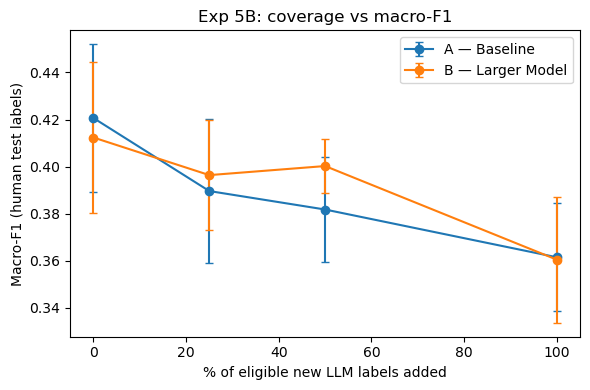

In [31]:

r5 = ResultsLog('exp5_resample_coverage').df()
cols = ('accuracy', 'macro_f1', 'recall_severe_damage', 'recall_mild_damage', 'recall_little_or_no_damage')
print('5A: resampling (trained models)')
display(mean_std(r5[(r5.experiment == 'exp5A') & (r5.model == 'trained')], ['config', 'condition', 'test_labels'], cols))
print('\n5B: coverage, tested on human labels (trained models)')
c5 = r5[(r5.experiment == 'exp5B') & (r5.model == 'trained')]
display(mean_std(c5, ['config', 'min_conf', 'coverage_fraction'], cols))
if not c5.empty:
    fig, ax = plt.subplots(figsize=(6, 4))
    for cfg, g in c5.groupby('config'):
        s = g.groupby('coverage_fraction')['macro_f1'].agg(['mean', 'std'])
        ax.errorbar(s.index * 100, s['mean'], yerr=s['std'], marker='o', capsize=3, label=cfg)
    ax.set_xlabel('% of eligible new LLM labels added'); ax.set_ylabel('Macro-F1 (human test labels)')
    ax.set_title('Exp 5B: coverage vs macro-F1'); ax.legend(); plt.tight_layout()
    plt.savefig(P4_DIR / 'exp5B_coverage_curve.png', dpi=150); plt.show()